# Layout, ownership, and the complete operation

Ownership identifies the logical element handled by a lane and slot. A storage
layout turns that element into an address:

$$O(r,\ell,s)=(r,4\ell+s),\quad L(r,c)=rH+c,\quad A=L\circ O.$$

**Evidence:** a synthetic CPU teaching map, not an MMA fragment, followed by nine
recorded L4 F1 comparisons. [Physical design](../docs/formulation.md#layouts).

1024 elements, exactly one owner each; all addresses in bounds.


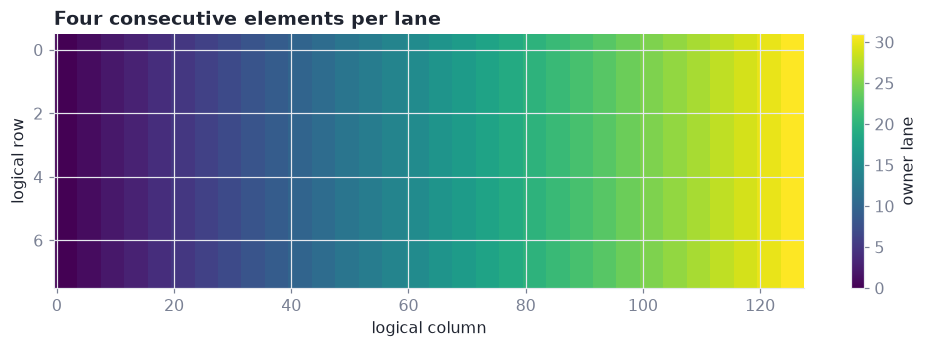

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
rows, lanes, slots = 8, 32, 4
width = lanes * slots
owners = np.empty((rows, width), dtype=int)
addresses = []
for row in range(rows):
    for lane in range(lanes):
        for slot in range(slots):
            col = slots * lane + slot
            addresses.append(row * width + col)
            owners[row, col] = lane
assert sorted(addresses) == list(range(rows * width))
print(f"{len(addresses)} elements, exactly one owner each; all addresses in bounds.")
fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(owners, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_xlabel("logical column"); ax.set_ylabel("logical row")
ax.set_title("Four consecutive elements per lane")
fig.colorbar(im, ax=ax, label="owner lane")
save(fig, "layout_ownership"); plt.show()


## Same shape, broken ownership

Replacing `4 * lane + slot` with `lane + slot` preserves the loop bounds but creates duplicate writers. Check addresses and coverage, not just shapes.

In [2]:
bad = [row * width + lane + slot
       for row in range(rows) for lane in range(lanes) for slot in range(slots)]
assert len(set(bad)) < rows * width
print("colliding writes:", len(bad) - len(set(bad)))
print("uncovered elements:", rows * width - len(set(bad)))


colliding writes: 744
uncovered elements: 744


## Correctness and performance remain separate

The historical xR38 revision passed its recorded correctness and sanitizer
checks, but regressed against its preceding revision in eight of nine cases.
Compiler spills are a plausible contributor, not an isolated causal measurement.

**Timed scope:** routing/alignment, gate/up and SwiGLU (F1). Down projection and
final combination are excluded. This replays the data; the historical kernel
and its harness are not distributed here.

faster than preceding revision: 1 of 9
faster than vLLM: 0 of 9


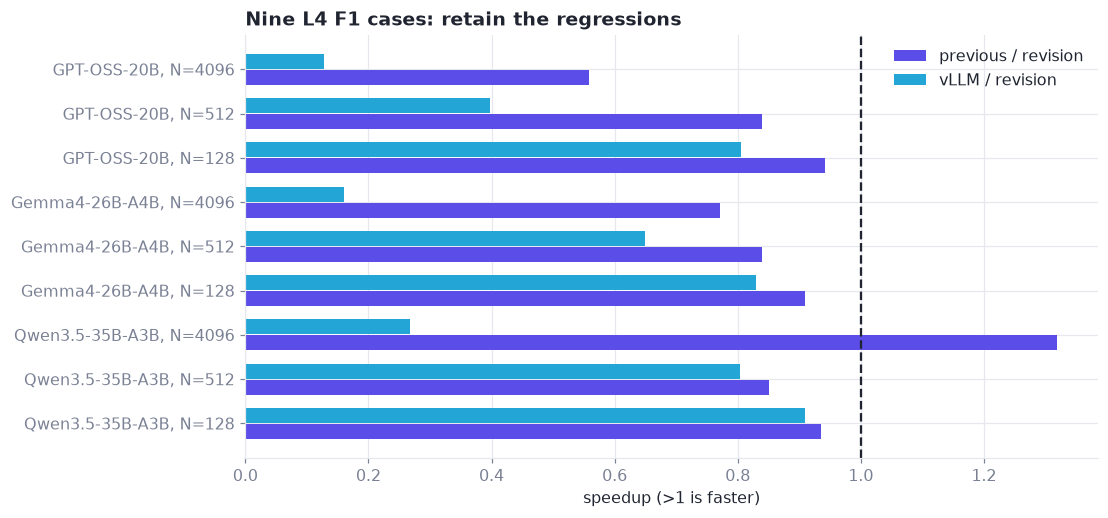

,model,N,xr38_us,previous_us,vllm_us,rel_l2
0,Qwen3.5-35B-A3B,128,5059.584141,4733.952045,4599.808216,0.003885
1,Qwen3.5-35B-A3B,512,5976.064205,5083.136082,4798.463821,0.005946
2,Qwen3.5-35B-A3B,4096,22122.495651,29181.951523,5935.103893,0.012132
3,Gemma4-26B-A4B,128,5331.967831,4851.712227,4426.752090,0.003988
4,Gemma4-26B-A4B,512,7094.272137,5957.632065,4606.976032,0.012777
5,Gemma4-26B-A4B,4096,42492.927551,32753.662109,6822.912216,0.014072
6,GPT-OSS-20B,128,5815.296173,5472.256184,4680.704117,0.006357
7,GPT-OSS-20B,512,12952.575684,10862.591743,5140.480042,0.012877
8,GPT-OSS-20B,4096,95940.605164,53638.145447,12335.103989,0.014555


In [3]:
f1 = pd.read_csv(DATA / "l4_f1.csv")
assert len(f1) == 9
prev, engine = f1.previous_us / f1.xr38_us, f1.vllm_us / f1.xr38_us
print("faster than preceding revision:", int((prev > 1).sum()), "of", len(f1))
print("faster than vLLM:", int((engine > 1).sum()), "of", len(f1))
y = np.arange(len(f1))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(y - .18, prev, .34, label="previous / revision", color=C["ours"])
ax.barh(y + .18, engine, .34, label="vLLM / revision", color=C["cyan"])
ax.axvline(1, ls="--", color=INK)
ax.set_yticks(y, [f"{m}, N={n}" for m, n in zip(f1.model, f1.N)])
ax.set_xlabel("speedup (>1 is faster)")
ax.set_title("Nine L4 F1 cases: retain the regressions"); ax.legend()
save(fig, "l4_f1_results"); plt.show()
display(f1[["model", "N", "xr38_us", "previous_us", "vllm_us", "rel_l2"]])


A uniquely owned address can still be overwritten before its consumer finishes. [WarpSpeed plans](02_warpspeed_plans.ipynb) add resource/phase accounting; [structural search](09_structural_search.ipynb) tests complete implementations.

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)